# StreamFlix Content Analytics — Phase 2: Exploratory Data Analysis

#### Now, we'll import libraries and load the six cleaned CSV files from data/cleaned/ and verify that their row and column counts match the datasets we cleaned in Phase 1.

In [2]:

import os
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

sns.set_theme(style="whitegrid")

data_path = "../data/cleaned"

subscribers = pd.read_csv(os.path.join(data_path, "subscribers.csv"))
titles = pd.read_csv(os.path.join(data_path, "titles.csv"))
watch_history = pd.read_csv(os.path.join(data_path, "watch_history.csv"))
ratings = pd.read_csv(os.path.join(data_path, "ratings.csv"))
reviews = pd.read_csv(os.path.join(data_path, "reviews.csv"))
watchlist = pd.read_csv(os.path.join(data_path, "watchlist.csv"))

datasets = {
    "Subscribers": subscribers,
    "Titles": titles,
    "Watch History": watch_history,
    "Ratings": ratings,
    "Reviews": reviews,
    "Watchlist": watchlist
}

for name, df in datasets.items():
    print(f"{name}: {df.shape[0]:,} rows × {df.shape[1]} columns")


Subscribers: 15,000 rows × 14 columns
Titles: 9,000 rows × 21 columns
Watch History: 650,000 rows × 10 columns
Ratings: 130,000 rows × 5 columns
Reviews: 110,000 rows × 7 columns
Watchlist: 65,000 rows × 5 columns


## Chart 1: Monthly Viewing Volume

##### This chart will show how the number of viewing sessions changes month by month and help us identify the busiest months.

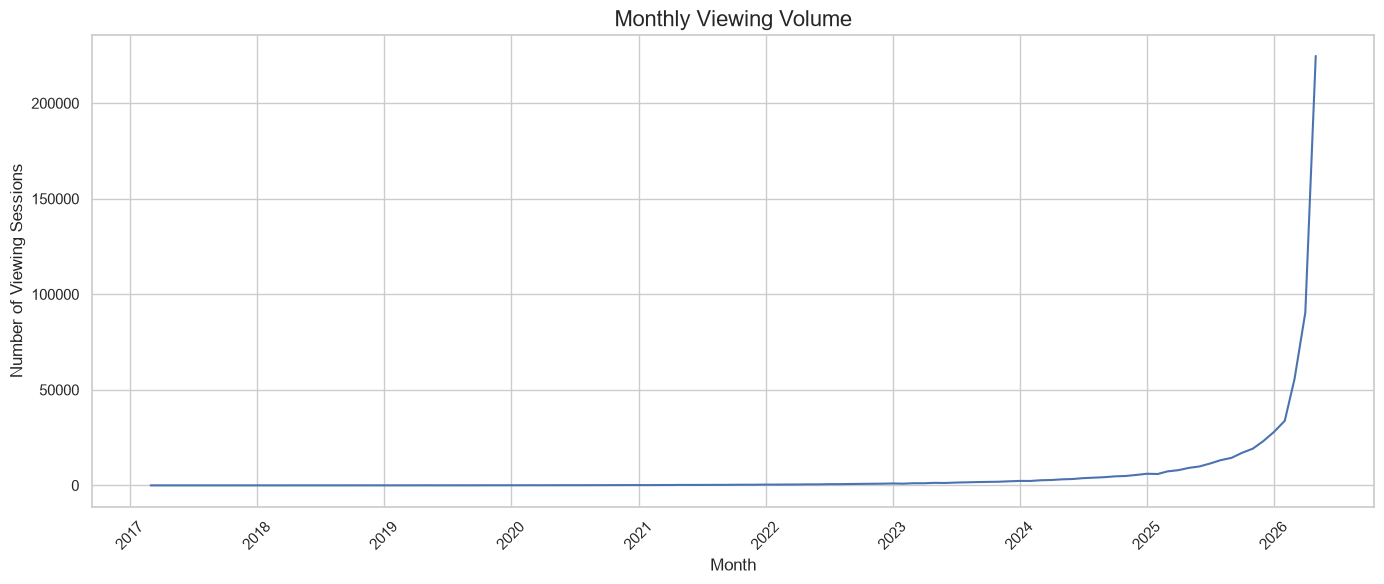

In [3]:

watch_history["watch_date"] = pd.to_datetime(watch_history["watch_date"])

monthly_sessions = watch_history.groupby(
    watch_history["watch_date"].dt.to_period("M")
).size()

monthly_sessions.index = monthly_sessions.index.to_timestamp()

plt.figure(figsize=(14, 6))
plt.plot(monthly_sessions.index, monthly_sessions.values, linewidth=1.5)
plt.title("Monthly Viewing Volume", fontsize=16)
plt.xlabel("Month")
plt.ylabel("Number of Viewing Sessions")
plt.xticks(rotation=45)
plt.tight_layout()
plt.savefig("../outputs/charts/01_monthly_viewing_volume.png", dpi=300, bbox_inches="tight")
plt.show()


##### The chart shows a very sharp increase in viewing sessions near 2026, reaching over 200,000 in a single month. Earlier months appear almost flat by comparison.

##### This might reflect genuine growth, but it could also mean that the latest month is incomplete or that the dates need to be checked. We shouldn't assume the cause from the chart alone. So, let's verify the monthly counts

In [4]:
print("Earliest watch date:", watch_history["watch_date"].min())
print("Latest watch date:", watch_history["watch_date"].max())
print("\nLast 12 months of viewing sessions:")
print(monthly_sessions.tail(12).to_string())
print("\nFive months with the highest viewing volume:")
print(monthly_sessions.sort_values(ascending=False).head(5).to_string())


Earliest watch date: 2017-03-10 00:00:00
Latest watch date: 2026-05-31 00:00:00

Last 12 months of viewing sessions:
watch_date
2025-06-01      9912
2025-07-01     11420
2025-08-01     13206
2025-09-01     14408
2025-10-01     17022
2025-11-01     19192
2025-12-01     23120
2026-01-01     27970
2026-02-01     33795
2026-03-01     55665
2026-04-01     90383
2026-05-01    224696

Five months with the highest viewing volume:
watch_date
2026-05-01    224696
2026-04-01     90383
2026-03-01     55665
2026-02-01     33795
2026-01-01     27970


##### We've identified an important anomaly: May 2026 has 224,696 viewing sessions, compared with 90,383 in April 2026. That's an increase of approximately 148.6% in one month.

##### Your date range is March 2017 to May 2026, which is consistent with the Data Dictionary's stated timeline through June 2026. However, the May spike is unusual enough that we should investigate it before drawing conclusions. So, let's check daily viewing volume in May 2026

In [5]:
may_data = watch_history[
    (watch_history["watch_date"] >= "2026-05-01") &
    (watch_history["watch_date"] < "2026-06-01")
]

print("Total May sessions:", len(may_data))
print("Number of distinct viewing days:", may_data["watch_date"].nunique())
print("\nSessions by day:")
print(may_data.groupby(may_data["watch_date"].dt.date).size().to_string())

Total May sessions: 224696
Number of distinct viewing days: 31

Sessions by day:
watch_date
2026-05-01     4047
2026-05-02     4175
2026-05-03     4295
2026-05-04     4444
2026-05-05     4420
2026-05-06     4591
2026-05-07     4689
2026-05-08     4883
2026-05-09     4915
2026-05-10     5093
2026-05-11     5242
2026-05-12     5463
2026-05-13     5556
2026-05-14     5813
2026-05-15     6093
2026-05-16     6192
2026-05-17     6232
2026-05-18     6551
2026-05-19     6808
2026-05-20     7149
2026-05-21     7403
2026-05-22     7834
2026-05-23     8154
2026-05-24     8697
2026-05-25     8959
2026-05-26     9934
2026-05-27    10606
2026-05-28    11481
2026-05-29    12550
2026-05-30    14200
2026-05-31    18227


##### This output gives us a clearer picture: May's viewing volume rises steadily from 4,047 sessions on May 1 to 18,227 on May 31. That is approximately a 350.4% increase from the first day to the last day.

##### However, the daily increase looks unusually consistent. We should check whether this pattern is present in earlier months, rather than assuming it represents genuine audience growth. So, now we'll compare daily viewing patterns across months

In [6]:
for month in ["2026-03", "2026-04", "2026-05"]:
    month_data = watch_history[
        watch_history["watch_date"].dt.strftime("%Y-%m") == month
    ]
    daily_sessions = month_data.groupby(month_data["watch_date"].dt.day).size()
    print(f"\n{month}")
    print(daily_sessions.to_string())



2026-03
watch_date
1     1445
2     1418
3     1449
4     1580
5     1460
6     1533
7     1488
8     1579
9     1658
10    1725
11    1649
12    1696
13    1722
14    1680
15    1661
16    1786
17    1813
18    1807
19    1920
20    1901
21    1930
22    1891
23    2008
24    2012
25    2054
26    2011
27    2113
28    2102
29    2149
30    2165
31    2260

2026-04
watch_date
1     2235
2     2250
3     2271
4     2382
5     2437
6     2494
7     2495
8     2554
9     2586
10    2665
11    2635
12    2834
13    2868
14    2965
15    2946
16    2989
17    2976
18    3092
19    3223
20    3240
21    3209
22    3370
23    3419
24    3596
25    3619
26    3721
27    3727
28    3745
29    3846
30    3994

2026-05
watch_date
1      4047
2      4175
3      4295
4      4444
5      4420
6      4591
7      4689
8      4883
9      4915
10     5093
11     5242
12     5463
13     5556
14     5813
15     6093
16     6192
17     6232
18     6551
19     6808
20     7149
21     7403
22     7834
23   

##### The output confirms that the unusual increase is not limited to a single day. Viewing sessions rise steadily throughout all three months, but the scale of that increase differs considerably.

| Month      | First day | Last day | Pattern             |
|------------|----------:|---------:|---------------------|
| March 2026 |     1,445 |    2,260 | Gradual increase    |
| April 2026 |     2,235 |    3,994 | Gradual increase    |
| May 2026   |     4,047 |   18,227 | Much steeper increase |

##### May's daily viewing volume rises by about 350% from its first to its last day. This is a data pattern worth investigating, not proof that the platform genuinely experienced that level of audience growth.

##### So, now we'll check whether the increase comes from more active subscribers. Let's count how many distinct subscribers watched something each day in March, April, and May. This will help us distinguish an increase in the number of viewers from an increase in sessions per viewer.

In [7]:
for month in ["2026-03", "2026-04", "2026-05"]:
    month_data = watch_history[
        watch_history["watch_date"].dt.strftime("%Y-%m") == month
    ]
    daily_viewers = month_data.groupby(
        month_data["watch_date"].dt.day
    )["subscriber_id"].nunique()
    print(f"\n{month}")
    print(daily_viewers.to_string())



2026-03
watch_date
1     1155
2     1144
3     1157
4     1222
5     1174
6     1227
7     1188
8     1253
9     1335
10    1355
11    1328
12    1340
13    1348
14    1315
15    1315
16    1373
17    1427
18    1414
19    1513
20    1480
21    1490
22    1468
23    1530
24    1526
25    1560
26    1550
27    1595
28    1610
29    1631
30    1672
31    1685

2026-04
watch_date
1     1692
2     1690
3     1686
4     1782
5     1801
6     1866
7     1823
8     1897
9     1877
10    1910
11    1978
12    2029
13    2045
14    2107
15    2127
16    2108
17    2112
18    2187
19    2251
20    2328
21    2271
22    2355
23    2394
24    2446
25    2526
26    2578
27    2581
28    2548
29    2617
30    2633

2026-05
watch_date
1     2724
2     2755
3     2883
4     2949
5     2915
6     2996
7     3015
8     3117
9     3135
10    3235
11    3314
12    3424
13    3458
14    3549
15    3775
16    3745
17    3813
18    3932
19    3997
20    4175
21    4216
22    4451
23    4560
24    4702
25   

##### This output gives us an important finding: the number of distinct daily viewers is also increasing, so the rise in viewing sessions is not explained solely by existing viewers watching repeatedly.

##### However, the increase is still unusually steep in May, so we'll quantify the relationship before deciding how to report it. So, now let's compare sessions per active viewer

In [8]:

for month in ["2026-03", "2026-04", "2026-05"]:
    month_data = watch_history[
        watch_history["watch_date"].dt.strftime("%Y-%m") == month
    ]
    daily_summary = month_data.groupby(
        month_data["watch_date"].dt.day
    ).agg(
        sessions=("subscriber_id", "size"),
        active_viewers=("subscriber_id", "nunique")
    )
    daily_summary["sessions_per_viewer"] = (
        daily_summary["sessions"] / daily_summary["active_viewers"]
    )
    print(f"\n{month}")
    print(daily_summary.tail(5).round(2).to_string())



2026-03
            sessions  active_viewers  sessions_per_viewer
watch_date                                               
27              2113            1595                 1.32
28              2102            1610                 1.31
29              2149            1631                 1.32
30              2165            1672                 1.29
31              2260            1685                 1.34

2026-04
            sessions  active_viewers  sessions_per_viewer
watch_date                                               
26              3721            2578                 1.44
27              3727            2581                 1.44
28              3745            2548                 1.47
29              3846            2617                 1.47
30              3994            2633                 1.52

2026-05
            sessions  active_viewers  sessions_per_viewer
watch_date                                               
27             10606            5389         

##### We've found a useful pattern. The average number of sessions per active viewer increases from roughly 1.3 in late March to 2.55 on May 31. Both daily active viewers and sessions per viewer are rising, so increased viewing activity appears to contribute to the spike.

##### However, the unusually consistent growth still deserves caution: this analysis alone cannot establish whether the pattern reflects real user behaviour or synthetic data generation.


### Observations For Chart 1:

1. Monthly viewing sessions increase substantially over the available timeline, with the highest volume recorded in May 2026 at 224,696 sessions.
2. Viewing activity accelerates sharply during March–May 2026. Daily active viewers and sessions per active viewer also increase, indicating that both the number of viewers and their viewing frequency contribute to the rise.
3. The unusually steep and consistent increase warrants further validation before being interpreted as genuine platform growth.



## Chart 2 — Monthly Watch Hours Trend

Analyse monthly watch hours to understand how total viewing time changes over the available timeline and identify periods of accelerated growth.


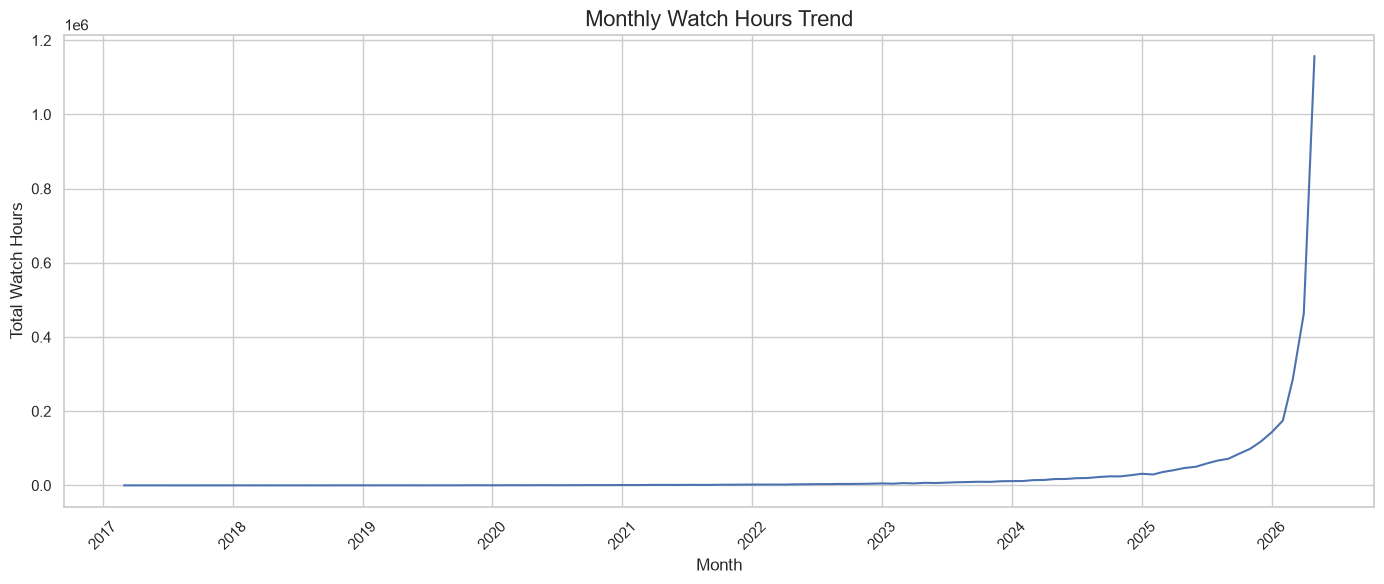

In [9]:

watch_history["watch_hours"] = watch_history["watch_duration_min"] / 60

monthly_watch_hours = watch_history.groupby(
    watch_history["watch_date"].dt.to_period("M")
)["watch_hours"].sum()

monthly_watch_hours.index = monthly_watch_hours.index.to_timestamp()

plt.figure(figsize=(14, 6))
plt.plot(monthly_watch_hours.index, monthly_watch_hours.values, linewidth=1.5)
plt.title("Monthly Watch Hours Trend", fontsize=16)
plt.xlabel("Month")
plt.ylabel("Total Watch Hours")
plt.xticks(rotation=45)
plt.tight_layout()
plt.savefig("../outputs/charts/02_monthly_watch_hours_trend.png", dpi=300, bbox_inches="tight")
plt.show()


##### Chart 2 shows the same sharp increase near May 2026 as Chart 1. We should document this pattern carefully rather than automatically interpreting it as genuine platform growth.


### Observations For Chart 2:

1. Monthly watch hours increase substantially over the timeline, with the highest viewing time recorded in May 2026.
2. Viewing time rises sharply during the final months of the dataset, particularly in March–May 2026, broadly matching the increase in monthly viewing sessions.
3. This sharp increase should be validated before being interpreted as genuine platform growth, as the chart alone cannot establish its cause.


##### Now, let's compare watch hours year over year. The PRD specifically asks you to compare year over year for Chart 2. Let's calculate annual watch hours before moving to Chart 3.

In [10]:

annual_watch_hours = watch_history.groupby(
    watch_history["watch_date"].dt.year
)["watch_hours"].sum()

print("Annual Watch Hours:")
print(annual_watch_hours.round(2).to_string())

print("\nYear-over-Year Percentage Change:")
print((annual_watch_hours.pct_change() * 100).round(2).to_string())


Annual Watch Hours:
watch_date
2017         45.76
2018        583.54
2019       1679.41
2020       5471.78
2021      15435.33
2022      37353.96
2023      89665.82
2024     223994.05
2025     733939.06
2026    2225299.02

Year-over-Year Percentage Change:
watch_date
2017        NaN
2018    1175.31
2019     187.80
2020     225.81
2021     182.09
2022     142.00
2023     140.04
2024     149.81
2025     227.66
2026     203.20


##### The results reveal a major pattern: annual watch hours increase substantially every year, with particularly large increases in 2025 and 2026.

##### However, 2026 is only a partial year (January–May), so its total should not be compared directly with full-year totals. The steep growth across the dataset also reinforces the need to validate the underlying pattern before attributing it to actual platform growth.


### Year-over-Year Observations (chart 2)

1. Annual watch hours increase consistently throughout the available dataset, indicating a strong upward trend in recorded viewing activity.
2. The year-over-year increase is particularly large in 2025, while 2026 records 2,225,299.02 watch hours through May alone.
3. The 2017 and 2026 figures represent partial years, and the unusually steep overall growth should be validated before drawing conclusions about platform performance.


## Chart 3 — Genre-wise Watch-Hours Share

Analyse the share of total viewing hours contributed by each primary genre to identify which genres account for the most viewing time.

In [11]:

print("Titles columns:")
print(titles.columns.tolist())

print("\nSample title records:")
print(titles.head(5).to_string())



Titles columns:
['title_id', 'title_name', 'type', 'primary_genre', 'country', 'language', 'release_year', 'date_added', 'maturity_rating', 'seasons', 'content_duration_min', 'is_original', 'license_type', 'director', 'cast', 'quality_score', 'popularity_score', 'license_cost_usd', 'license_expiry', 'total_watch_hours', 'total_plays']

Sample title records:
    title_id             title_name     type primary_genre      country language  release_year  date_added maturity_rating  seasons  content_duration_min  is_original           license_type      director                                                  cast  quality_score  popularity_score  license_cost_usd license_expiry  total_watch_hours  total_plays
0  TTL200000        Toronto Requiem  TV Show        Comedy  South Korea   Korean          2026  2026-04-05               R        6                  2754         True               Original   Ravi Nguyen      Rosa Ferrari, Aria Cohen, Nina Kim, Felix Santos           68.6            

The columns needed for Chart 3 — Genre-wise Watch-Hours Share are:

- titles["title_id"] identifies each title.
- titles["primary_genre"] identifies its genre.
- watch_history["title_id"] connects viewing sessions to titles.
- watch_history["watch_duration_min"] provides the viewing duration in minutes.

We'll join the two datasets using title_id, convert viewing minutes into hours, and calculate each genre's share of total watch hours.

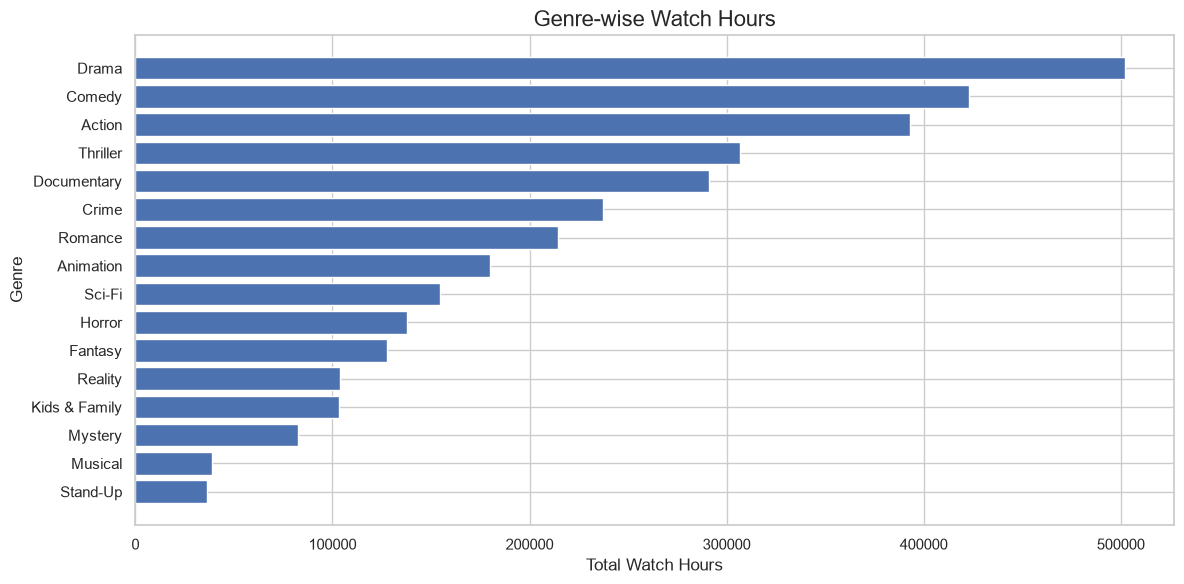

In [12]:

genre_data = watch_history.merge(
    titles[["title_id", "primary_genre"]],
    on="title_id",
    how="left"
)

genre_watch_hours = genre_data.groupby("primary_genre")["watch_duration_min"].sum() / 60
genre_watch_hours = genre_watch_hours.sort_values(ascending=False)

plt.figure(figsize=(12, 6))
plt.barh(genre_watch_hours.index, genre_watch_hours.values)
plt.title("Genre-wise Watch Hours", fontsize=16)
plt.xlabel("Total Watch Hours")
plt.ylabel("Genre")
plt.gca().invert_yaxis()
plt.tight_layout()
plt.savefig("../outputs/charts/03_genre-wise_watch_hours.png", dpi=300, bbox_inches="tight")
plt.show()


##### Now, let's calculate each genre's percentage of total watch hours rather than reporting only the totals.

In [13]:
genre_watch_share = (genre_watch_hours / genre_watch_hours.sum()) * 100

print("Genre-wise Watch-Hours Share (%):")
print(genre_watch_share.round(2).to_string())

print("\nTop 5 Genres by Watch-Hours Share:")
print(genre_watch_share.head(5).round(2).to_string())


Genre-wise Watch-Hours Share (%):
primary_genre
Drama            15.06
Comedy           12.69
Action           11.79
Thriller          9.21
Documentary       8.74
Crime             7.12
Romance           6.43
Animation         5.40
Sci-Fi            4.63
Horror            4.14
Fantasy           3.84
Reality           3.12
Kids & Family     3.09
Mystery           2.48
Musical           1.17
Stand-Up          1.09

Top 5 Genres by Watch-Hours Share:
primary_genre
Drama          15.06
Comedy         12.69
Action         11.79
Thriller        9.21
Documentary     8.74



### Observations For Chart 3:

1. Drama contributes the largest share of total viewing time at 15.06%, followed by Comedy at 12.69% and Action at 11.79%.
2. The top three genres collectively account for 39.54% of total watch hours, indicating that viewing time is concentrated among several leading genres.
3. Stand-Up and Musical have the smallest shares at 1.09% and 1.17%, respectively.



## Chart 4 — Content Type Split

Compare the share of total watch hours between Movies and TV Shows to identify which content type accounts for more viewing time.


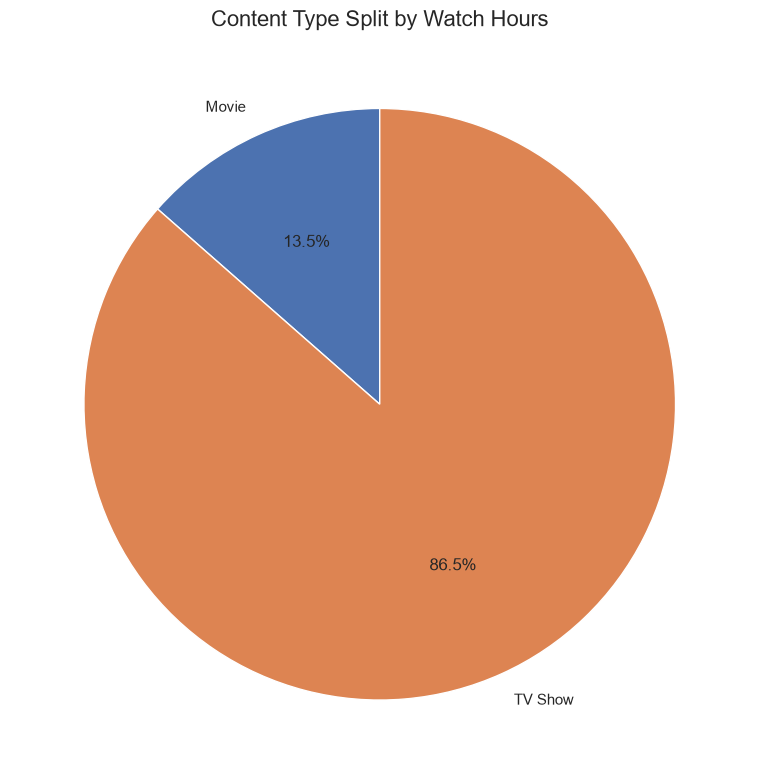

Watch hours by content type:
type
Movie       450858.81
TV Show    2882608.92

Watch-hours share (%):
type
Movie      13.53
TV Show    86.47


In [14]:
type_data = watch_history.merge(
    titles[["title_id", "type"]],
    on="title_id",
    how="left"
)

type_watch_hours = type_data.groupby("type")["watch_duration_min"].sum() / 60
type_watch_share = type_watch_hours / type_watch_hours.sum() * 100

plt.figure(figsize=(8, 8))
plt.pie(
    type_watch_hours,
    labels=type_watch_hours.index,
    autopct="%1.1f%%",
    startangle=90
)
plt.title("Content Type Split by Watch Hours", fontsize=16)
plt.tight_layout()
plt.savefig("../outputs/charts/04_content_type_split.png", dpi=300, bbox_inches="tight")
plt.show()

print("Watch hours by content type:")
print(type_watch_hours.round(2).to_string())

print("\nWatch-hours share (%):")
print(type_watch_share.round(2).to_string())



### Observations For Chart 4:

1. TV Shows account for 86.47% of total watch hours (2,882,608.92 hours), while Movies contribute 13.53% (450,858.81 hours).
2. TV Shows generate approximately 6.4 times as many watch hours as Movies, indicating that viewing time is heavily concentrated in episodic content.
3. The content-type split shows a clear preference for TV Shows in recorded viewing activity, although this measures watch time rather than the number of titles or individual viewers.



## Chart 5 — Top 10 Countries by Watch Hours

Identify the ten countries with the highest total watch hours to compare viewing consumption across content-producing countries.


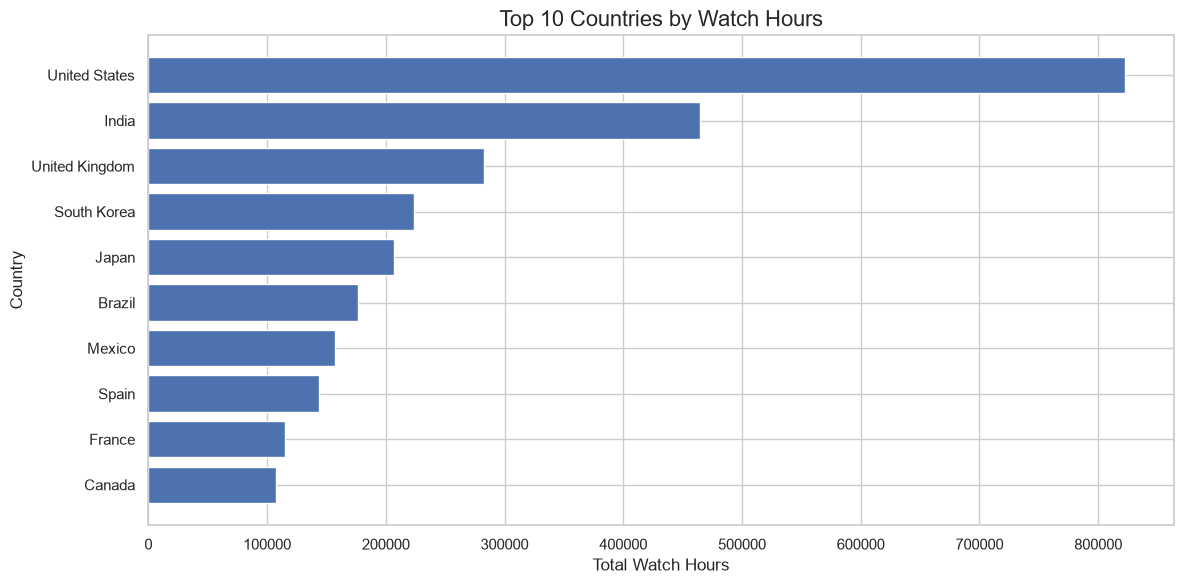

Top 10 countries by watch hours:
country
United States     822684.68
India             464337.76
United Kingdom    282946.39
South Korea       223476.40
Japan             207130.87
Brazil            176353.60
Mexico            157176.86
Spain             143656.40
France            115011.76
Canada            107072.95


In [15]:
country_data = watch_history.merge(
    titles[["title_id", "country"]],
    on="title_id",
    how="left"
)

country_watch_hours = country_data.groupby("country")["watch_duration_min"].sum() / 60
country_watch_hours = country_watch_hours.dropna().sort_values(ascending=False).head(10)

plt.figure(figsize=(12, 6))
plt.barh(country_watch_hours.index, country_watch_hours.values)
plt.title("Top 10 Countries by Watch Hours", fontsize=16)
plt.xlabel("Total Watch Hours")
plt.ylabel("Country")
plt.gca().invert_yaxis()
plt.tight_layout()
plt.savefig("../outputs/charts/05_top_10_countries_watch_hours.png", dpi=300, bbox_inches="tight")
plt.show()

print("Top 10 countries by watch hours:")
print(country_watch_hours.round(2).to_string())



### Observations For Chart 5:

1. The United States ranks first with 822,684.68 watch hours, followed by India with 464,337.76 hours and the United Kingdom with 282,946.39 hours.
2. The United States generates approximately 1.77 times as many watch hours as India, making it the leading country by this measure.
3. Among the ten countries shown, Canada records the lowest total at 107,072.95 watch hours. These results reflect the countries associated with titles, not necessarily subscribers' locations.


## Chart 6 — Subscriber Plan Distribution

A pie chart showing how many subscribers are on Basic, Standard, and Premium plans.

In [16]:

print("Subscriber columns:")
print(subscribers.columns.tolist())

print("\nPlan distribution:")
print(subscribers["plan_type"].value_counts(dropna=False).to_string())


Subscriber columns:
['subscriber_id', 'signup_date', 'country', 'region', 'age', 'gender', 'plan_type', 'monthly_price_usd', 'household_size', 'primary_device', 'payment_method', 'tenure_months', 'is_active', 'churn_date']

Plan distribution:
plan_type
Standard          6100
Basic with Ads    4458
Premium           4442


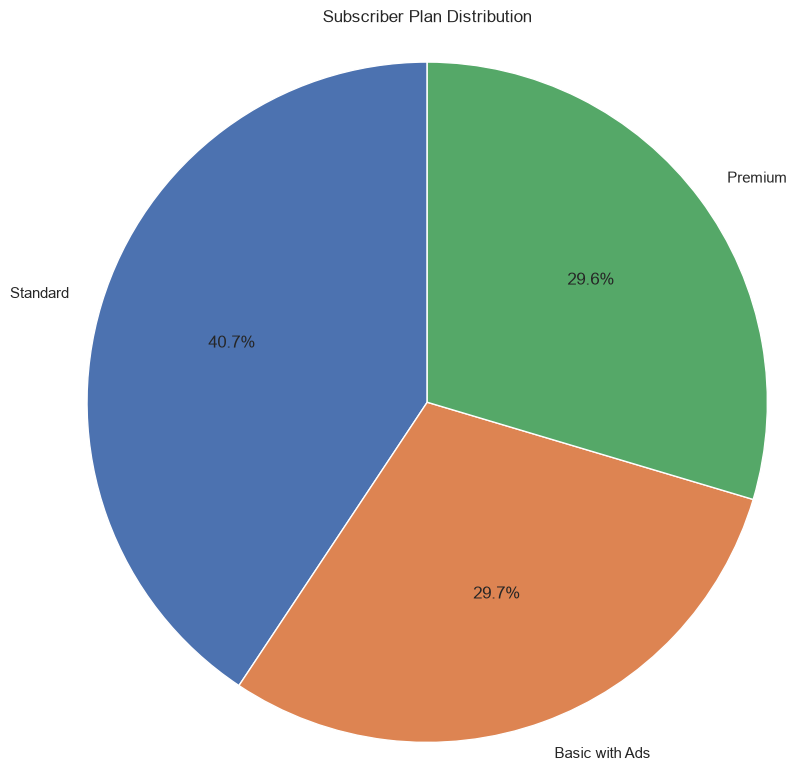

In [17]:

plan_counts = subscribers["plan_type"].value_counts()

plt.figure(figsize=(8, 8))
plt.pie(plan_counts, labels=plan_counts.index, autopct="%1.1f%%", startangle=90)
plt.title("Subscriber Plan Distribution")
plt.axis("equal")
plt.tight_layout()
plt.savefig("../outputs/charts/06_subscriber_plan_distribution.png", dpi=300, bbox_inches="tight")
plt.show()


### Observation For Chart 6: 

The Standard plan is the most popular, accounting for 40.7% of subscribers. Basic with Ads and Premium have nearly equal shares, each representing approximately 30% of the subscriber base.


## Chart 7 — Device Usage

Analyse viewing sessions by device type to identify which devices subscribers use most frequently to watch StreamFlix content.


In [18]:
print("Device distribution:")
print(watch_history["device"].value_counts(dropna=False).to_string())


Device distribution:
device
Smart TV           221446
Mobile             175605
Laptop              96408
Tablet              65276
Game Console        52322
Streaming Stick     38943


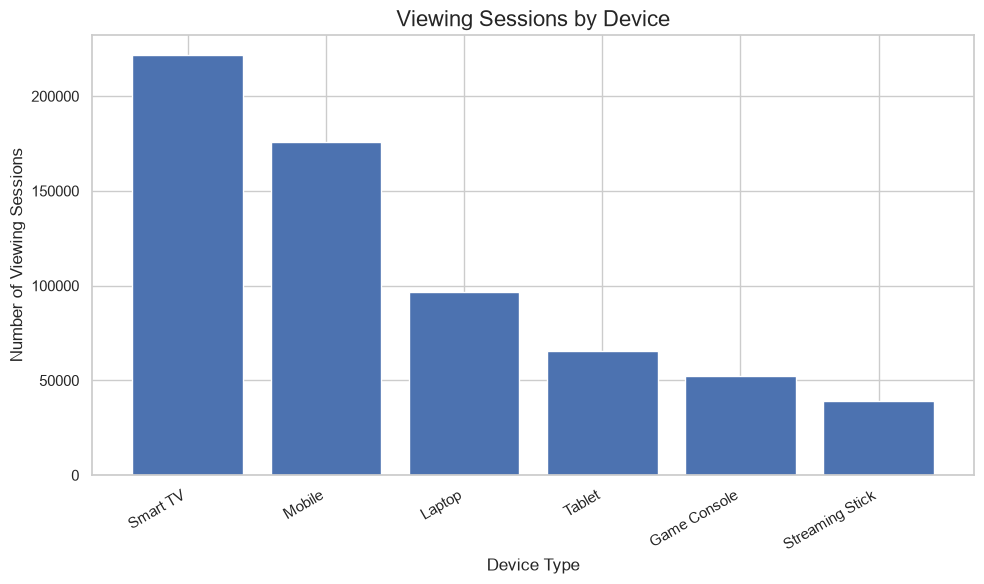

Device-wise viewing sessions:
device
Smart TV           221446
Mobile             175605
Laptop              96408
Tablet              65276
Game Console        52322
Streaming Stick     38943


In [20]:
device_counts = watch_history["device"].value_counts()

plt.figure(figsize=(10, 6))
plt.bar(device_counts.index, device_counts.values)
plt.title("Viewing Sessions by Device", fontsize=16)
plt.xlabel("Device Type")
plt.ylabel("Number of Viewing Sessions")
plt.xticks(rotation=30, ha="right")
plt.tight_layout()
plt.savefig("../outputs/charts/07_device_usage.png", dpi=300, bbox_inches="tight")
plt.show()

print("Device-wise viewing sessions:")
print(device_counts.to_string())



### Observations For Chart 7:

1. Smart TVs are the most frequently used devices, accounting for 221,446 viewing sessions, followed by Mobile devices with 175,605 sessions.
2. Smart TVs and Mobile devices together account for approximately 59.5% of all viewing sessions.
3. Streaming Sticks record the lowest usage with 38,943 sessions, while Laptop, Tablet, and Game Console usage falls between Mobile and Streaming Stick.



## Chart 8 — Age Distribution of Subscribers

Analyse the distribution of subscriber ages using a histogram to identify the most common age ranges among StreamFlix subscribers.


##### First, let's inspect the age distribution in the subscribers dataset.

In [21]:

print("Subscriber age statistics:")
print(subscribers["age"].describe().round(2))

print("\nAge range:")
print("Minimum age:", subscribers["age"].min())
print("Maximum age:", subscribers["age"].max())

Subscriber age statistics:
count    15000.00
mean        35.62
std         12.53
min         13.00
25%         27.00
50%         35.00
75%         44.00
max         85.00
Name: age, dtype: float64

Age range:
Minimum age: 13
Maximum age: 85


##### The subscriber dataset contains 15,000 subscribers, with ages ranging from 13 to 85 years. The average and median ages are quite close, suggesting that the distribution is reasonably centred around the mid-30s. Now, let's plot the histogram.

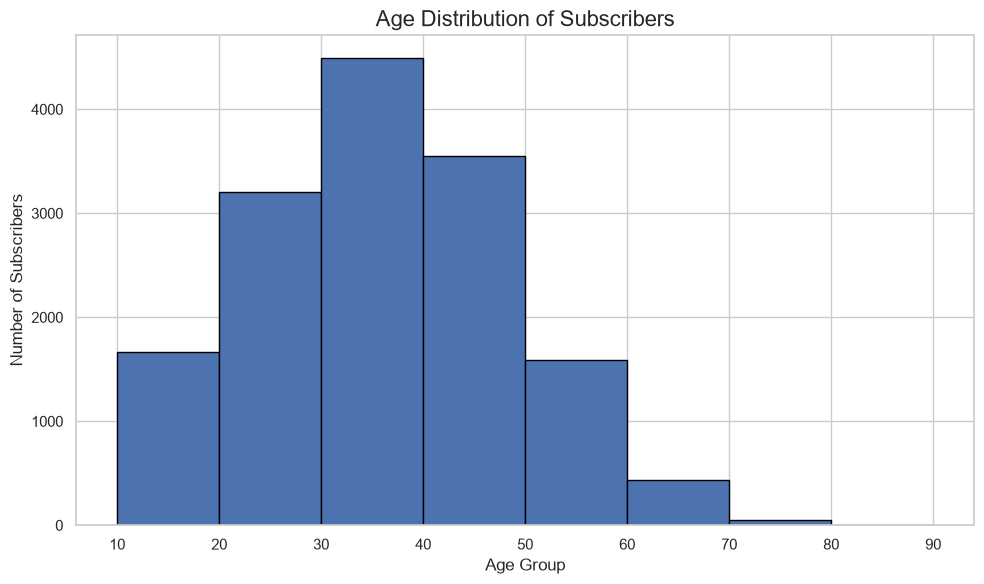

In [22]:

plt.figure(figsize=(10, 6))
plt.hist(subscribers["age"], bins=range(10, 91, 10), edgecolor="black")
plt.title("Age Distribution of Subscribers", fontsize=16)
plt.xlabel("Age Group")
plt.ylabel("Number of Subscribers")
plt.xticks(range(10, 91, 10))
plt.tight_layout()
plt.savefig("../outputs/charts/08_age_distribution.png", dpi=300, bbox_inches="tight")
plt.show()



### Observations For Chart 8:

1. The 30–40 age group has the highest subscriber representation, followed by the 40–50 age group.
2. Most StreamFlix subscribers are between 20 and 50 years old, with the average subscriber age being 35.62 years.
3. Subscriber representation declines considerably after age 50, with relatively few subscribers above 70 years.


##### Now, We'll connect subscriber ages with viewing records, calculate total watch hours for each age group and identify which age group watches the most.

In [23]:

age_data = watch_history.merge(
    subscribers[["subscriber_id", "age"]],
    on="subscriber_id",
    how="left"
)

age_data["age_group"] = pd.cut(
    age_data["age"],
    bins=[10, 20, 30, 40, 50, 60, 70, 90],
    right=False
)

age_group_watch_hours = age_data.groupby(
    "age_group", observed=False
)["watch_duration_min"].sum() / 60

print("Watch hours by age group:")
print(age_group_watch_hours.round(2).to_string())

print("\nAge group with highest watch hours:")
print(age_group_watch_hours.idxmax())


Watch hours by age group:
age_group
[10, 20)     368467.55
[20, 30)     644609.73
[30, 40)    1001949.58
[40, 50)     850402.10
[50, 60)     373724.25
[60, 70)      85039.03
[70, 90)       9275.49

Age group with highest watch hours:
[30, 40)



### Additional Viewing Behaviour Analysis (chart 8):

1. Subscribers aged 30–39 generate the highest total viewing time at 1,001,949.58 hours, followed by the 40–49 age group at 850,402.10 hours.
2. The 30–49 age groups together contribute the largest portion of recorded viewing activity.
3. Total watch hours decline substantially among subscribers aged 60 and above.

##### We've now answered both parts of the age analysis: the largest subscriber age group and the age group generating the most watch hours.



## Chart 9 — Completion Rate by Genre

Analyse the percentage of completed viewing sessions across different genres to identify which genres viewers are most likely to finish.

First, let's verify the completion percentage and genre data together.


In [24]:
print("Completion percentage statistics:")
print(watch_history["completion_pct"].describe().round(2))

print("\nCompletion status distribution:")
print(watch_history["completed"].value_counts(dropna=False).to_string())


Completion percentage statistics:
count    650000.00
mean         65.31
std          22.61
min           1.00
25%          49.20
50%          68.30
75%          84.10
max         100.00
Name: completion_pct, dtype: float64

Completion status distribution:
completed
False    550637
True      99363


| Metric                       |   Result |
|------------------------------|---------:|
| Average completion percentage |   65.31% |
| Median completion percentage  |   68.30% |
| Fully completed sessions      |   99,363 |
| Incomplete sessions           |  550,637 |
| Total sessions                |  650,000 |

Approximately 15.29% of viewing sessions are marked as completed.

The PRD asks for Completion Rate by Genre — Which genres get finished?

We'll define completion rate as:

Completion Rate = Completed Sessions / Total Sessions * 100

This is more appropriate for answering which genres viewers actually finish. We'll use the Boolean completed column rather than averaging completion_pct.

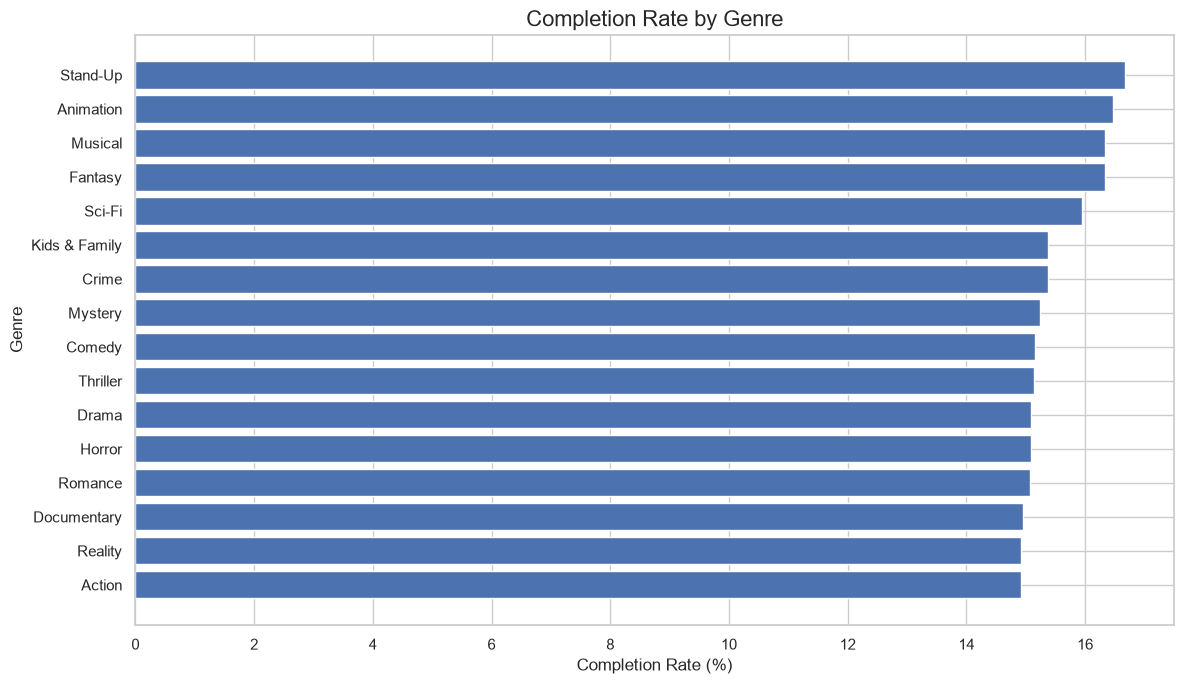

Completion Rate by Genre:
               total_sessions  completed_sessions  completion_rate
primary_genre                                                     
Stand-Up                 7993                1332            16.66
Animation               29208                4812            16.47
Musical                  7425                1213            16.34
Fantasy                 26407                4312            16.33
Sci-Fi                  33157                5290            15.95
Kids & Family           18338                2821            15.38
Crime                   44153                6791            15.38
Mystery                 18074                2754            15.24
Comedy                  84455               12803            15.16
Thriller                58589                8867            15.13
Drama                   95624               14432            15.09
Horror                  28122                4243            15.09
Romance                 44210       

In [25]:

completion_data = watch_history.merge(
    titles[["title_id", "primary_genre"]],
    on="title_id",
    how="left"
)

genre_completion = completion_data.groupby("primary_genre").agg(
    total_sessions=("completed", "count"),
    completed_sessions=("completed", "sum")
)

genre_completion["completion_rate"] = (
    genre_completion["completed_sessions"] /
    genre_completion["total_sessions"]
) * 100

genre_completion = genre_completion.sort_values(
    "completion_rate", ascending=False
)

plt.figure(figsize=(12, 7))
plt.barh(genre_completion.index, genre_completion["completion_rate"])
plt.title("Completion Rate by Genre", fontsize=16)
plt.xlabel("Completion Rate (%)")
plt.ylabel("Genre")
plt.gca().invert_yaxis()
plt.tight_layout()
plt.savefig("../outputs/charts/09_completion_rate_by_genre.png", dpi=300, bbox_inches="tight")
plt.show()

print("Completion Rate by Genre:")
print(genre_completion.round(2).to_string())



### Observations For Chart 9:

1. Stand-Up has the highest completion rate at 16.66%, followed by Animation at 16.47% and Musical at 16.34%.
2. Action records the lowest completion rate at 14.92%, closely followed by Reality at 14.93%.
3. Completion rates across all genres range from 14.92% to 16.66%, indicating relatively small differences in the proportion of completed viewing sessions across genres.



## Chart 10 — Review Sentiment Breakdown

Analyse the distribution of positive, neutral, and negative reviews to understand overall viewer sentiment toward StreamFlix content.

First, let's inspect the sentiment distribution in your reviews dataset.


In [26]:

print("Review columns:")
print(reviews.columns.tolist())

print("\nReview sentiment distribution:")
print(reviews["sentiment"].value_counts(dropna=False).to_string())


Review columns:
['review_id', 'subscriber_id', 'title_id', 'review_text', 'sentiment', 'helpful_votes', 'review_date']

Review sentiment distribution:
sentiment
Positive    75007
Neutral     22759
Negative    12234


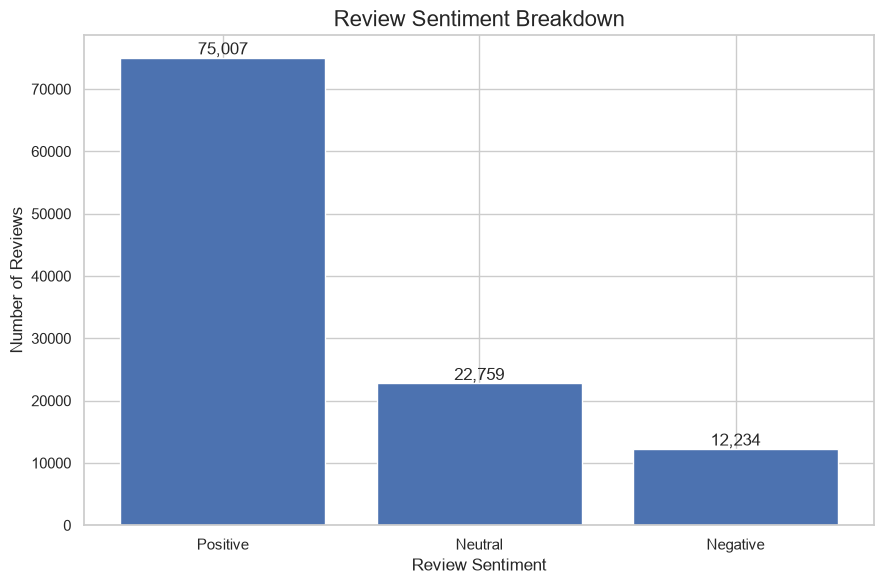

Review Sentiment Counts:
sentiment
Positive    75007
Neutral     22759
Negative    12234

Review Sentiment Share (%):
sentiment
Positive    68.19
Neutral     20.69
Negative    11.12


In [27]:

sentiment_counts = reviews["sentiment"].value_counts()

plt.figure(figsize=(9, 6))
plt.bar(sentiment_counts.index, sentiment_counts.values)

plt.title("Review Sentiment Breakdown", fontsize=16)
plt.xlabel("Review Sentiment")
plt.ylabel("Number of Reviews")

for i, count in enumerate(sentiment_counts.values):
    plt.text(i, count, f"{count:,}", ha="center", va="bottom")

plt.tight_layout()
plt.savefig("../outputs/charts/10_review_sentiment_breakdown.png", dpi=300, bbox_inches="tight")
plt.show()

print("Review Sentiment Counts:")
print(sentiment_counts.to_string())

print("\nReview Sentiment Share (%):")
print((sentiment_counts / len(reviews) * 100).round(2).to_string())



### Observations For Chart 10:

1. Positive reviews dominate the feedback, accounting for 75,007 reviews (68.19%) out of 110,000 total reviews.
2. Neutral reviews represent 20.69% (22,759), while negative reviews account for 11.12% (12,234).
3. The predominance of positive reviews suggests generally favourable viewer feedback, although negative reviews still represent an opportunity to investigate viewer dissatisfaction.
